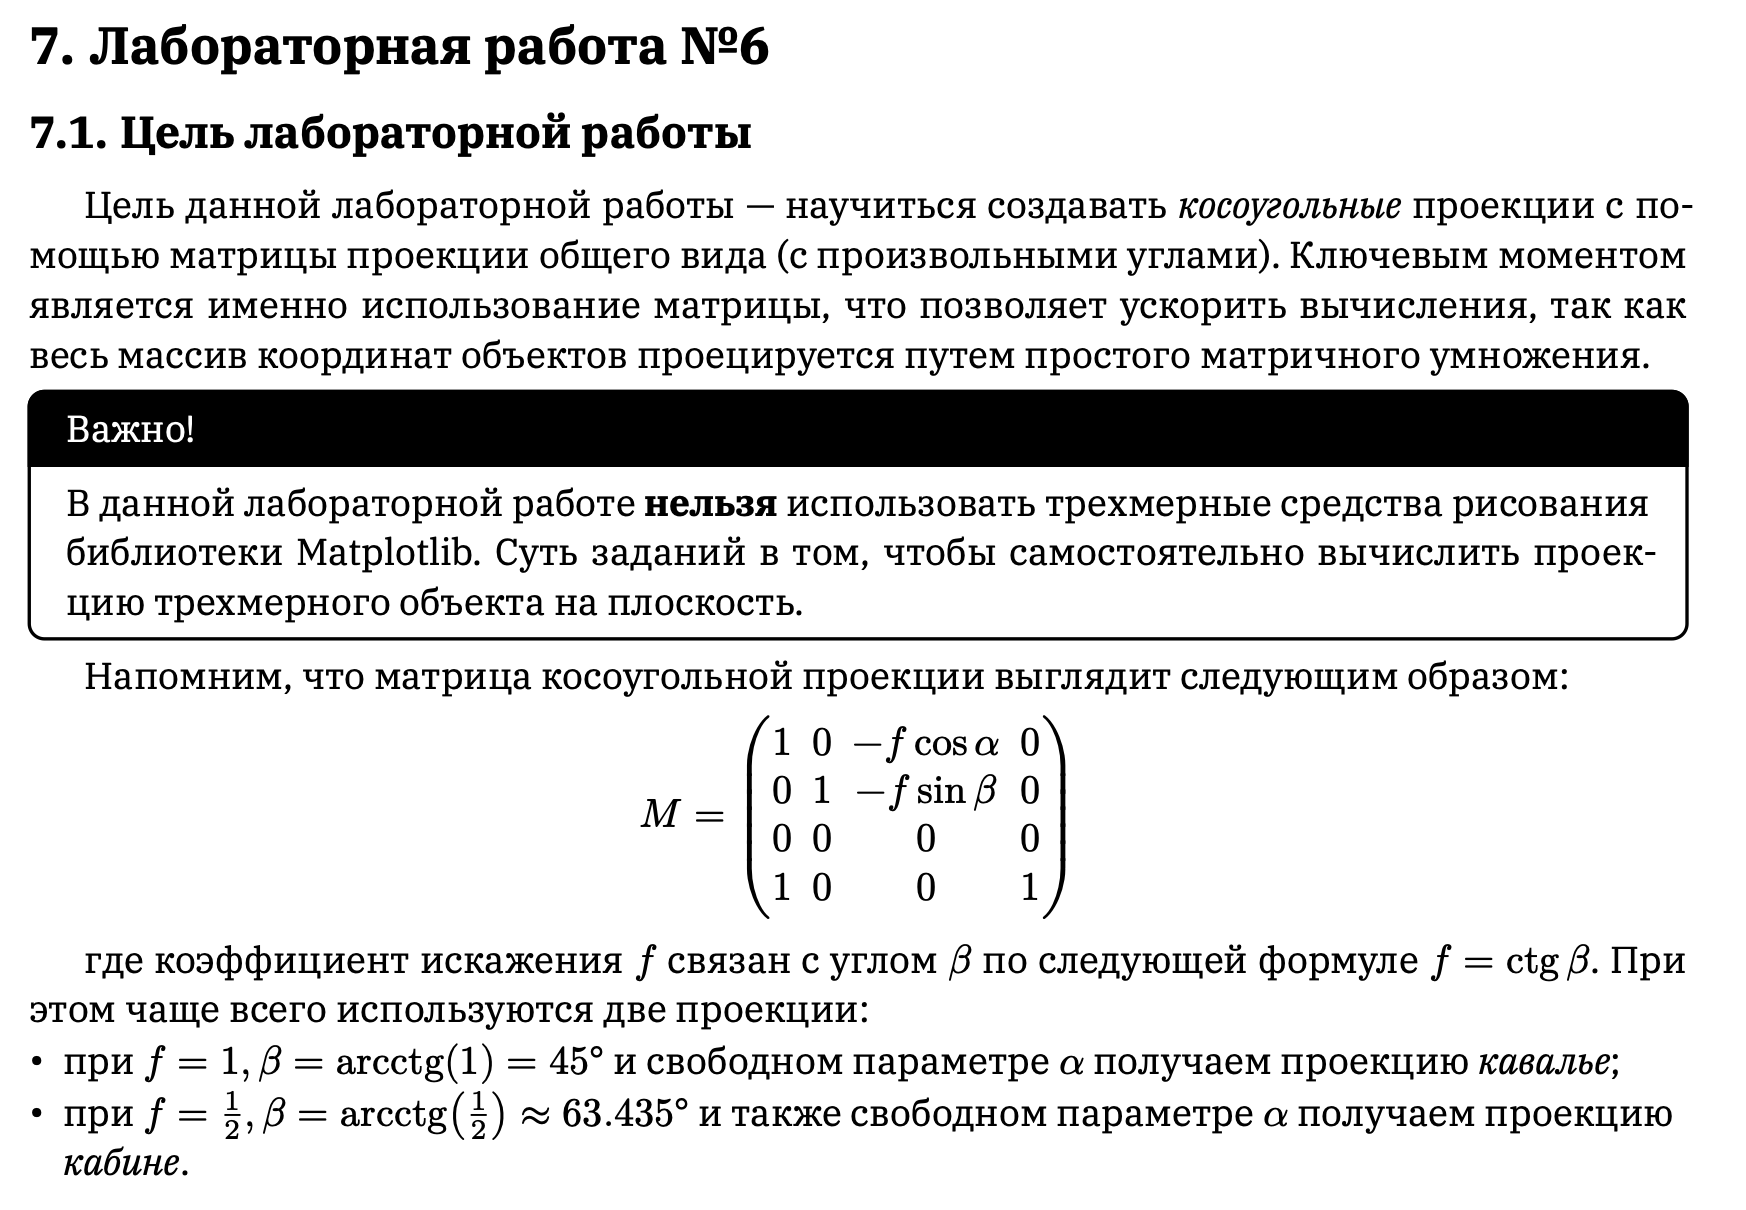

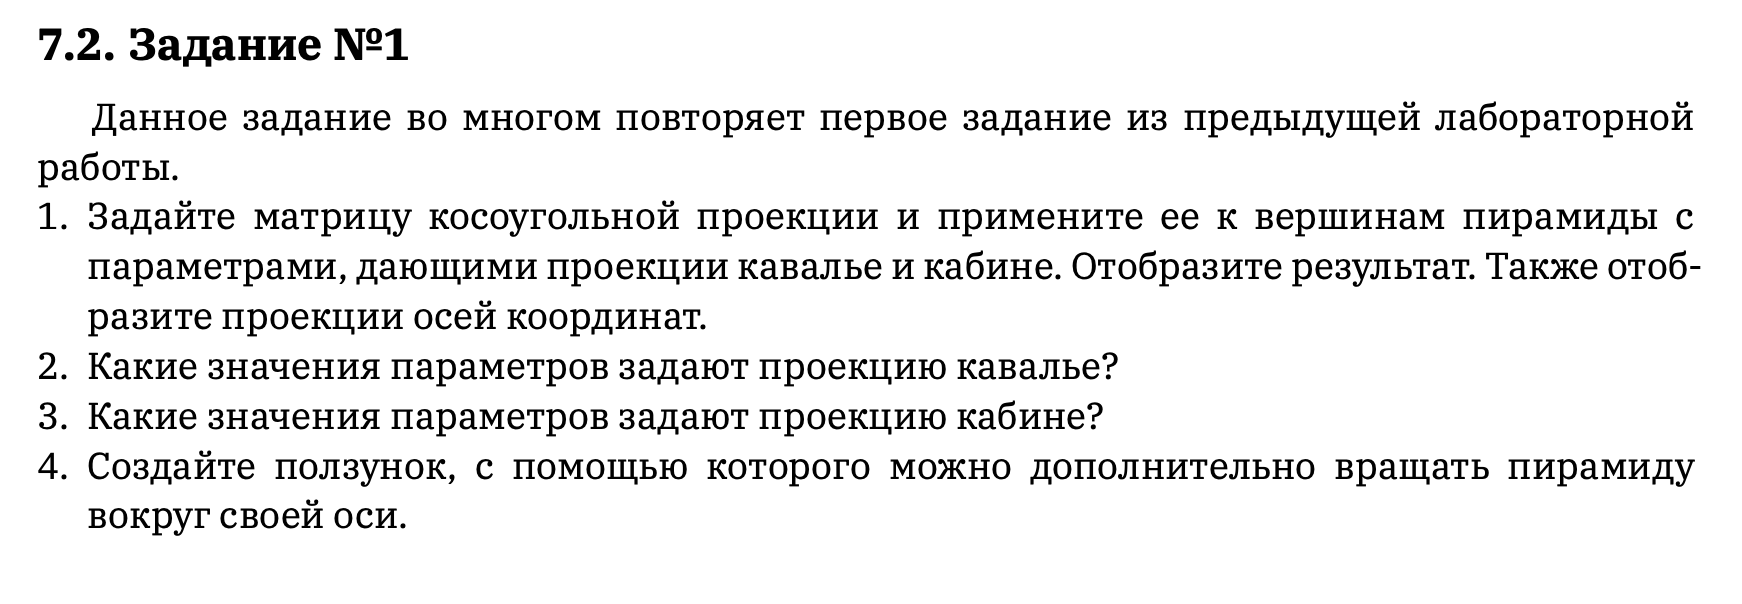

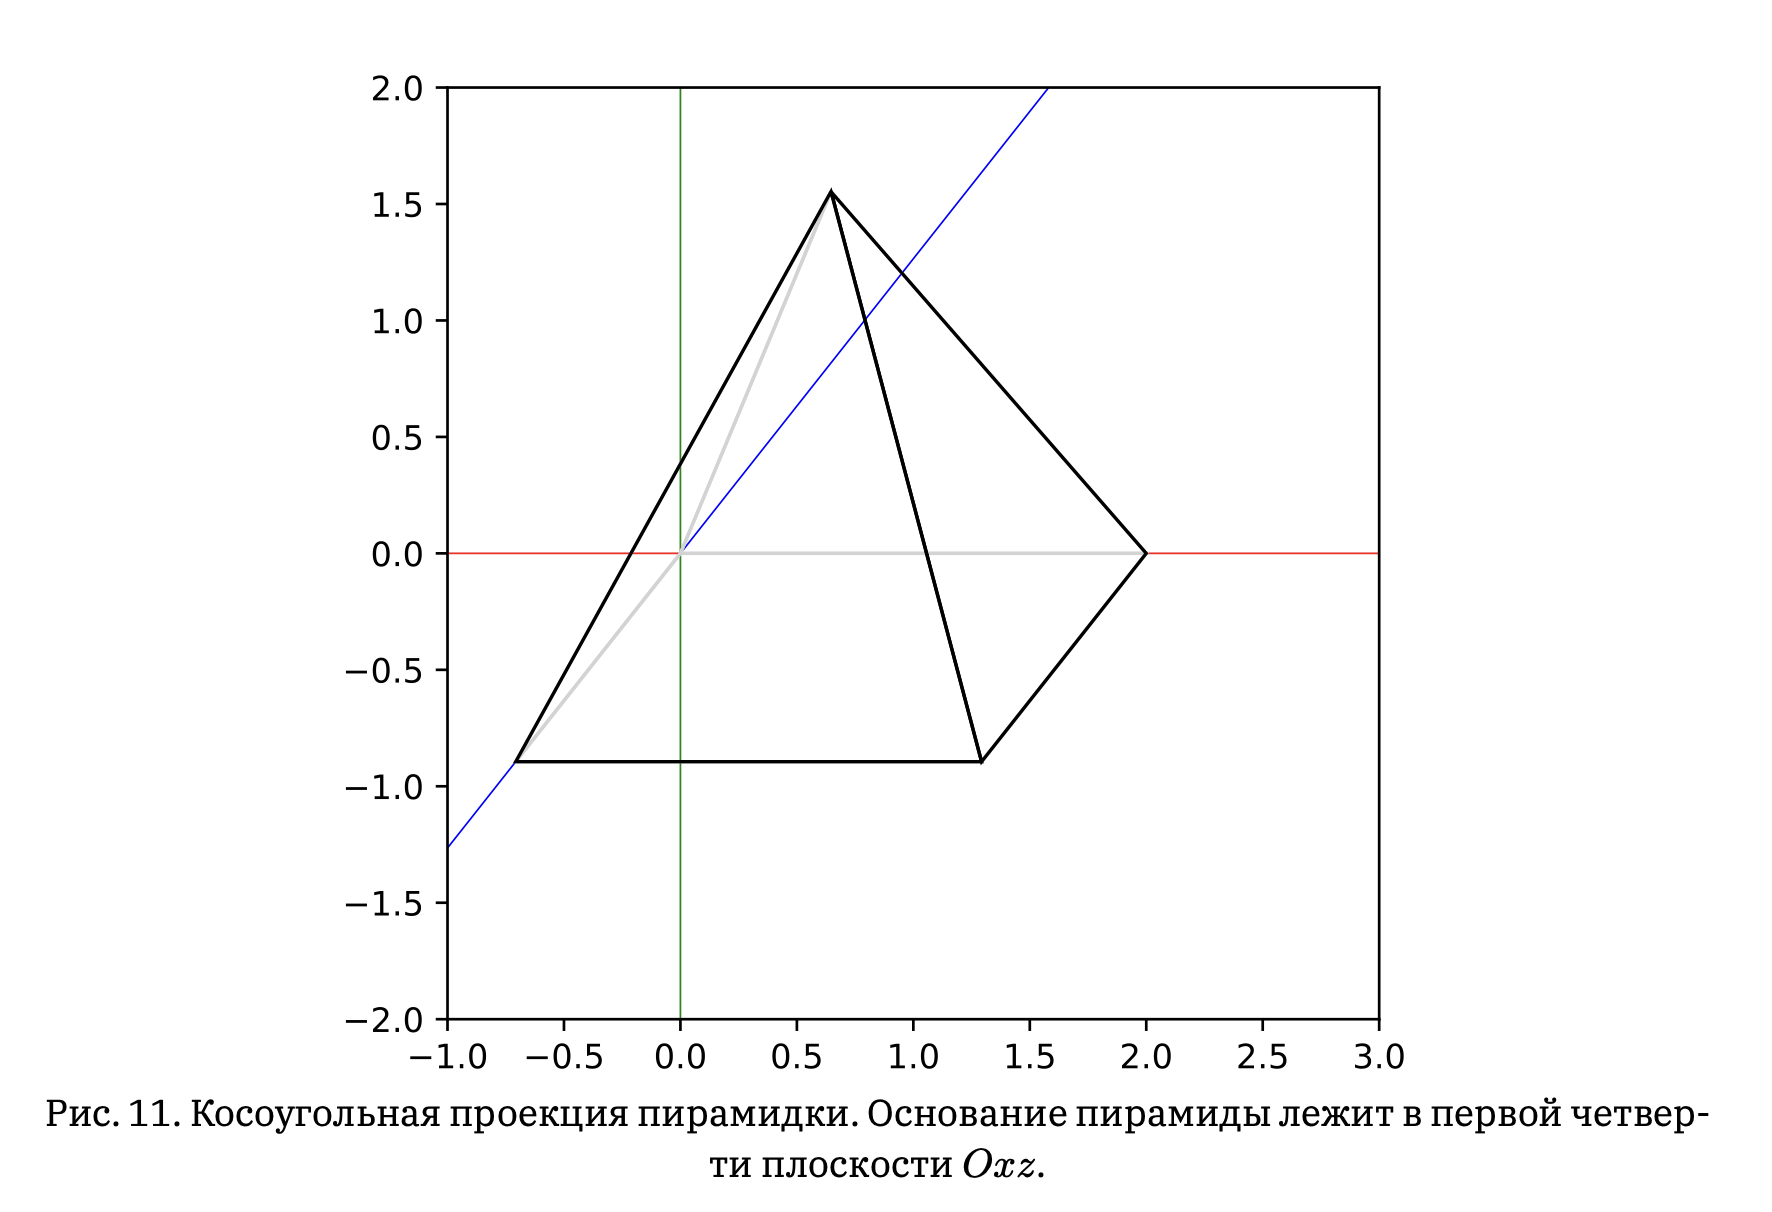

## 1. Матрица косоугольной проекции (кавалье и кабине)

###  Общая формула для косоугольной проекции:

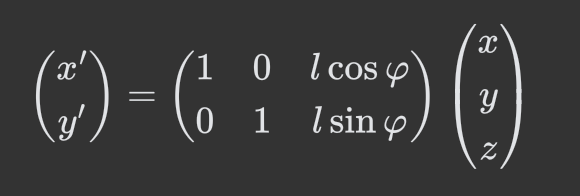

- l — коэффициент искажения (обычно 1 для кавалье, 0.5 для кабине)
- 𝜙 — угол проекции (обычно 45° для кавалье и кабине)


In [1]:
# 2. Вершины пирамиды и базисные векторы

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from ipywidgets import interact, FloatSlider

# Вершины пирамиды
pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])
pyramid_faces = [
    [0, 1, 2, 3],   # основание
    [0, 1, 4],
    [1, 2, 4],
    [2, 3, 4],
    [3, 0, 4]
]
basis = np.eye(3)

In [2]:
# 3. Функция косоугольной проекции

def oblique_projection_matrix(l=1.0, phi_deg=45):
    phi = np.radians(phi_deg)
    P = np.array([
        [1, 0, l * np.cos(phi)],
        [0, 1, l * np.sin(phi)]
    ])
    return P

In [4]:
# 4. Вращение пирамиды вокруг оси (например, высоты)

def rotation_matrix(axis, theta_deg):
    theta = np.radians(theta_deg)
    axis = np.array(axis, dtype=float)
    axis = axis / np.linalg.norm(axis)
    x, y, z = axis
    c = np.cos(theta)
    s = np.sin(theta)
    C = 1 - c
    R = np.array([
        [c + x*x*C, x*y*C - z*s, x*z*C + y*s],
        [y*x*C + z*s, c + y*y*C, y*z*C - x*s],
        [z*x*C - y*s, z*y*C + x*s, c + z*z*C]
    ])
    return R

In [6]:
# 5. Визуализация

def plot_oblique_pyramid(l=1.0, phi_deg=45, theta=0.0):
    # Вращаем пирамиду вокруг оси высоты (через вершину 4 и центр основания)
    base_center = np.mean(pyramid_vertices[:4], axis=0)
    axis = pyramid_vertices[4] - base_center
    R = rotation_matrix(axis, theta)
    pyramid_rot = (pyramid_vertices - base_center) @ R.T + base_center

    # Проецируем пирамиду
    P = oblique_projection_matrix(l, phi_deg)
    proj = (P @ pyramid_rot.T).T

    # Проецируем базисные векторы
    basis_proj = (P @ basis.T).T

    fig, ax = plt.subplots(figsize=(7,7))
    # Грани пирамиды
    for face in pyramid_faces:
        pts = proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='orange', edgecolor='black', alpha=0.8))
    # Подписи вершин
    for i, (x, y) in enumerate(proj):
        ax.text(x, y, f'{i}', color='red', fontsize=12)
    # Оси
    colors = ['r', 'g', 'b']
    for i in range(3):
        ax.arrow(0, 0, basis_proj[i,0], basis_proj[i,1], head_width=0.1, head_length=0.2, fc=colors[i], ec=colors[i], linewidth=2)
        ax.text(basis_proj[i,0]*1.1, basis_proj[i,1]*1.1, f"${'xyz'[i]}$", color=colors[i], fontsize=14)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(f"Косоугольная проекция пирамиды\nl={l}, φ={phi_deg}°, θ={theta}°")
    ax.grid(True)
    plt.show()

In [7]:
# 6. Интерактивный виджет

interact(
    plot_oblique_pyramid,
    l=FloatSlider(value=1.0, min=0.0, max=1.0, step=0.01, description='l'),
    phi_deg=FloatSlider(value=45, min=0, max=90, step=1, description='φ (°)'),
    theta=FloatSlider(value=0, min=0, max=360, step=1, description='Вращение (°)')
)

interactive(children=(FloatSlider(value=1.0, description='l', max=1.0, step=0.01), FloatSlider(value=45.0, des…

<function __main__.plot_oblique_pyramid(l=1.0, phi_deg=45, theta=0.0)>

## 7. Ответы на вопросы

- Какие значения параметров задают проекцию кавалье? l = 1, 𝜙 = 45

- Какие значения параметров задают проекцию кабине?l = 0.5, 𝜙 = 45

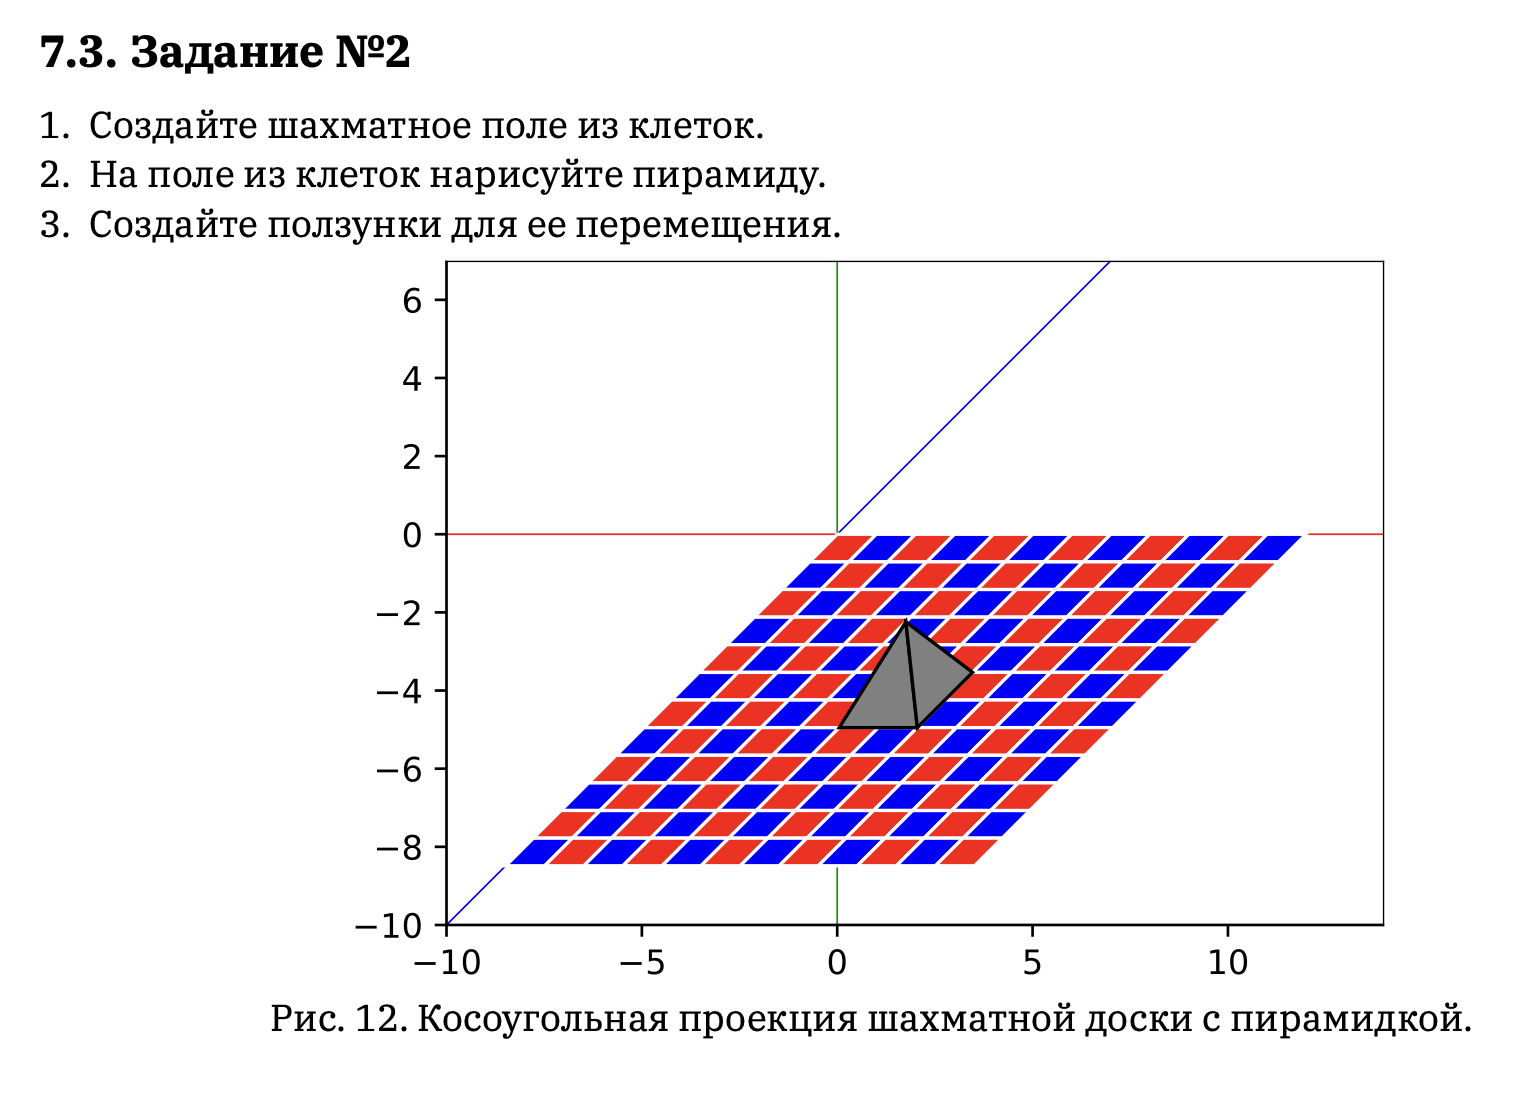

In [12]:
# 1. Функция косоугольной проекции (кавалье по умолчанию)
def oblique_projection_matrix(l=1.0, phi_deg=45):
    phi = np.radians(phi_deg)
    P = np.array([
        [1, 0, l * np.cos(phi)],
        [0, 1, l * np.sin(phi)]
    ])
    return P

# 2. Шахматное поле
def chessboard_field(n=8):
    square = np.array([
        [0, 0, 0],
        [1, 0, 0],
        [1, 0, 1],
        [0, 0, 1]
    ])
    squares = []
    colors = []
    for i in range(n):
        for j in range(n):
            sq = square + np.array([i, 0, j])
            squares.append(sq)
            colors.append('white' if (i+j)%2==0 else 'gray')
    return squares, colors

# 3. Вершины пирамиды
pyramid_vertices = np.array([
    [1, 0, 1],
    [-1, 0, 1],
    [-1, 0, -1],
    [1, 0, -1],
    [0, 2, 0]
])
pyramid_faces = [
    [0, 1, 2, 3],   # основание
    [0, 1, 4],
    [1, 2, 4],
    [2, 3, 4],
    [3, 0, 4]
]

# 4. Визуализация
def plot_oblique_chess_and_pyramid(px=0.0, py=0.0, pz=0.0, n=8, l=1.0, phi_deg=45):
    P = oblique_projection_matrix(l, phi_deg)
    # Шахматное поле
    squares, colors = chessboard_field(n)
    fig, ax = plt.subplots(figsize=(8,8))
    for sq, color in zip(squares, colors):
        sq_proj = (P @ sq.T).T
        ax.add_patch(Polygon(sq_proj, closed=True, facecolor=color, edgecolor='black', alpha=0.7))
    # Пирамида (сдвигаем на (px, py, pz))
    pyramid_shifted = pyramid_vertices + np.array([px, py, pz])
    proj = (P @ pyramid_shifted.T).T
    for face in pyramid_faces:
        pts = proj[face]
        ax.add_patch(Polygon(pts, closed=True, facecolor='orange', edgecolor='black', alpha=0.9))
    # Подписи вершин пирамиды
    for i, (x, y) in enumerate(proj):
        ax.text(x, y, f'{i}', color='red', fontsize=12)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title("Косоугольное шахматное поле с пирамидой")
    ax.set_xlim(-2, n+3)
    ax.set_ylim(-2, n+3)
    plt.grid(True)
    plt.show()

# 5. Интерактивные ползунки для перемещения пирамиды
interact(
    plot_oblique_chess_and_pyramid,
    px=FloatSlider(value=0, min=0, max=7, step=0.1, description='x'),
    py=FloatSlider(value=0, min=0, max=5, step=0.1, description='y'),
    pz=FloatSlider(value=0, min=0, max=7, step=0.1, description='z'),
    n=IntSlider(value=8, min=4, max=12, step=1, description='Размер поля'),
    l=FloatSlider(value=1.0, min=0.0, max=1.0, step=0.01, description='l'),
    phi_deg=FloatSlider(value=45, min=0, max=90, step=1, description='φ (°)')
)

interactive(children=(FloatSlider(value=0.0, description='x', max=7.0), FloatSlider(value=0.0, description='y'…

<function __main__.plot_oblique_chess_and_pyramid(px=0.0, py=0.0, pz=0.0, n=8, l=1.0, phi_deg=45)>